# Task 3 – Frequent Word Groups (Bigrams & Trigrams)

Single words lose context. *"free"* alone is ambiguous; *"free entry"* or *"free prize"* is not.

**N-grams** are contiguous sequences of N words. I analyse:
- **Bigrams** (N=2): two-word phrases
- **Trigrams** (N=3): three-word phrases

Analysed separately for HAM and SPAM to surface class-specific phraseology.

In [7]:
from IPython.display import display
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from sms_analysis import load_dataset
from sms_analysis.analysis import top_ngrams
from sms_analysis.visualization import plot_ngrams, save_figure

DATASET = Path("../assignment/3D8026C4.zip/SMSSpamCollection")
OUTPUTS = Path("outputs")

dataset   = load_dataset(DATASET)
ham_texts  = [m.text for m in dataset.ham]
spam_texts = [m.text for m in dataset.spam]

## Bigrams

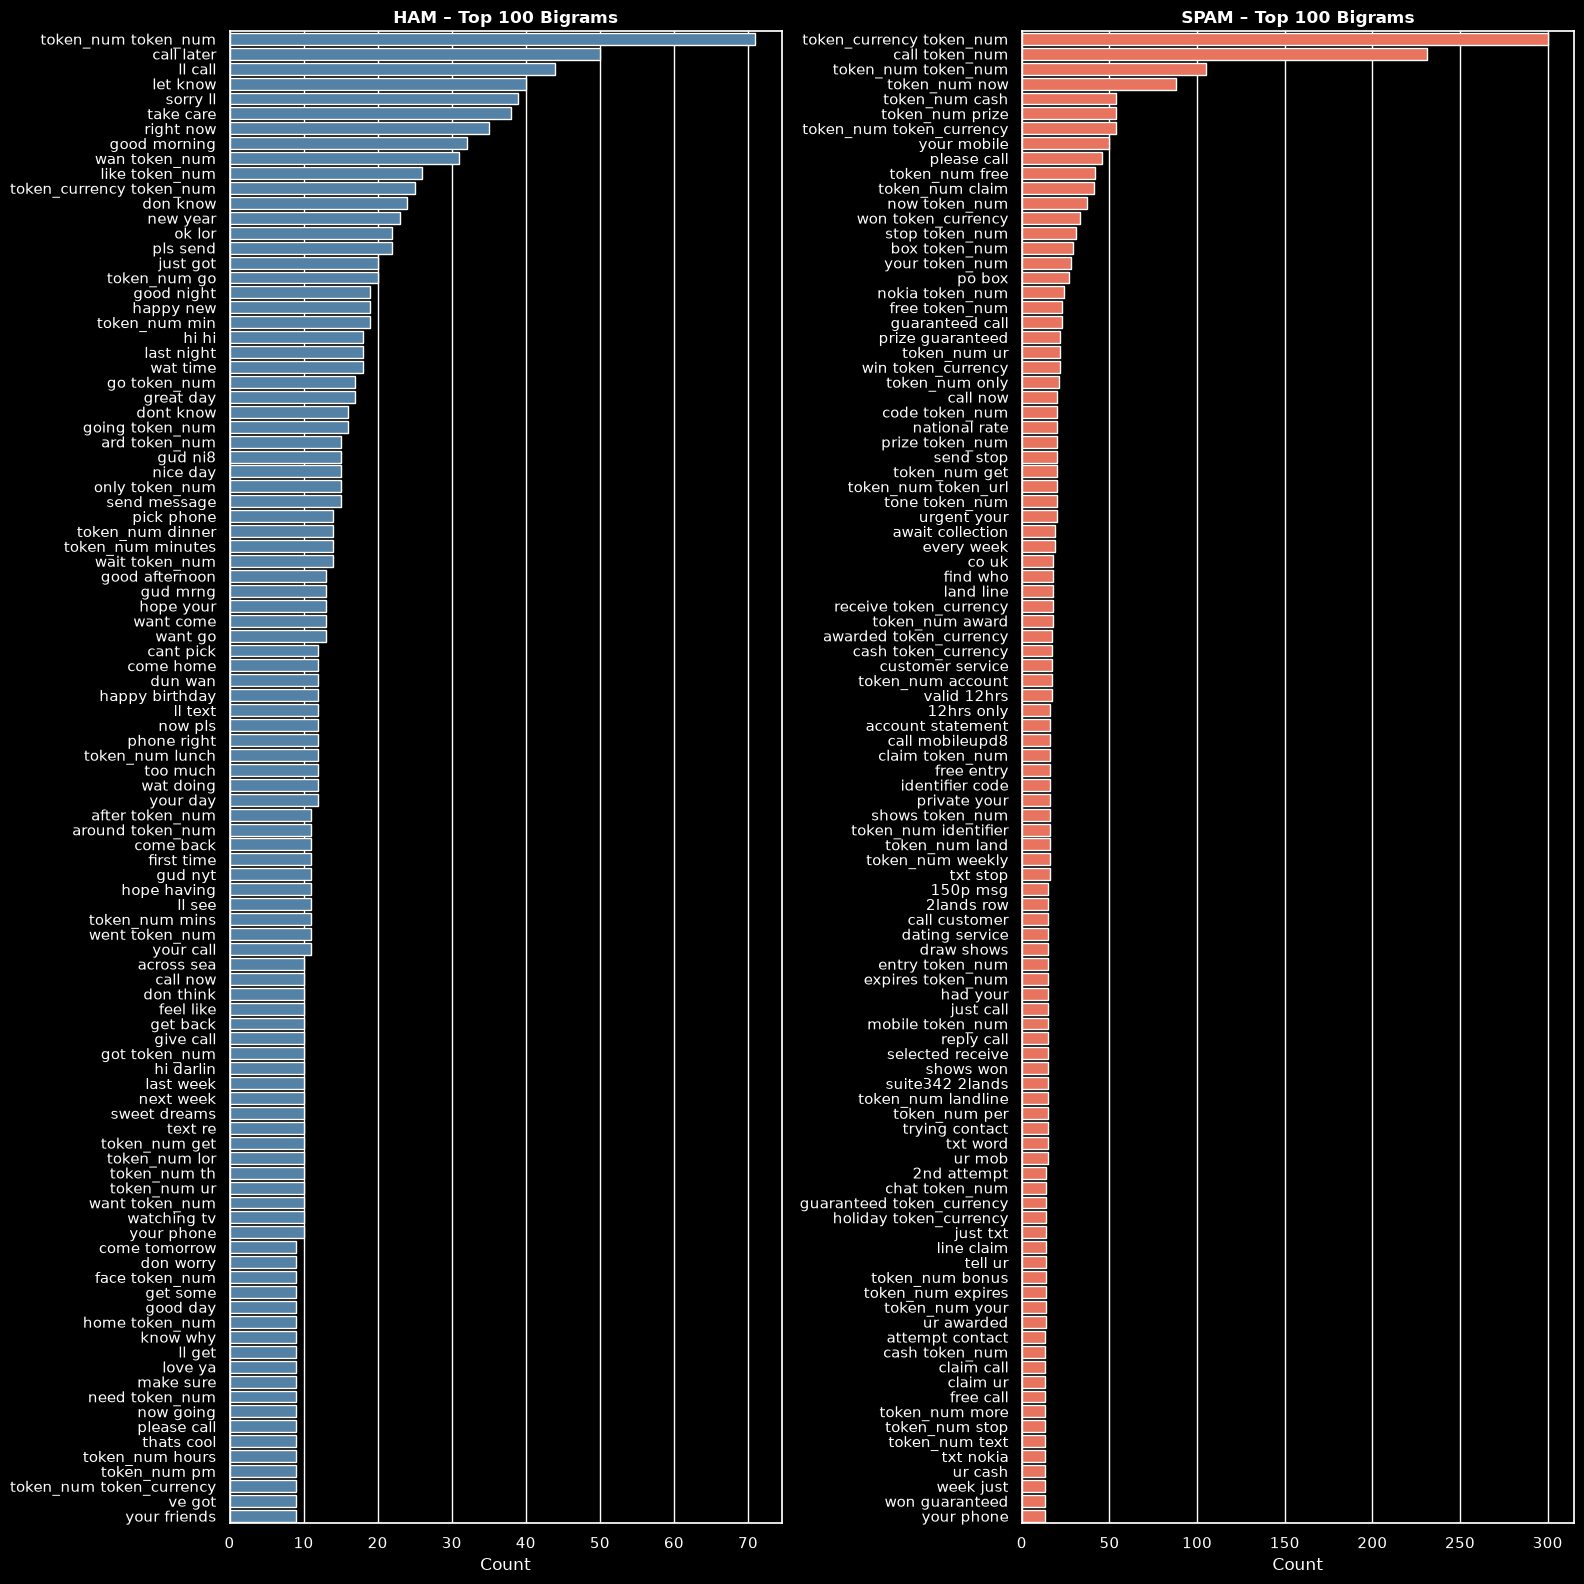

In [8]:
TOP_K      = 100
FIG_HEIGHT = 16

df_bigram_ham  = top_ngrams(ham_texts,  n=2, top_k=TOP_K)
df_bigram_spam = top_ngrams(spam_texts, n=2, top_k=TOP_K)

fig, axes = plt.subplots(1, 2, figsize=(16, FIG_HEIGHT))
sns.barplot(data=df_bigram_ham,  x="count", y="ngram", ax=axes[0], color="steelblue")
sns.barplot(data=df_bigram_spam, x="count", y="ngram", ax=axes[1], color="tomato")
axes[0].set_title(f"HAM – Top {TOP_K} Bigrams",  fontweight="bold")
axes[1].set_title(f"SPAM – Top {TOP_K} Bigrams", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Count")
    ax.set_ylabel("")
plt.tight_layout()
display(fig)
save_figure(fig, OUTPUTS / "03_bigrams_by_class.png")

## Trigrams

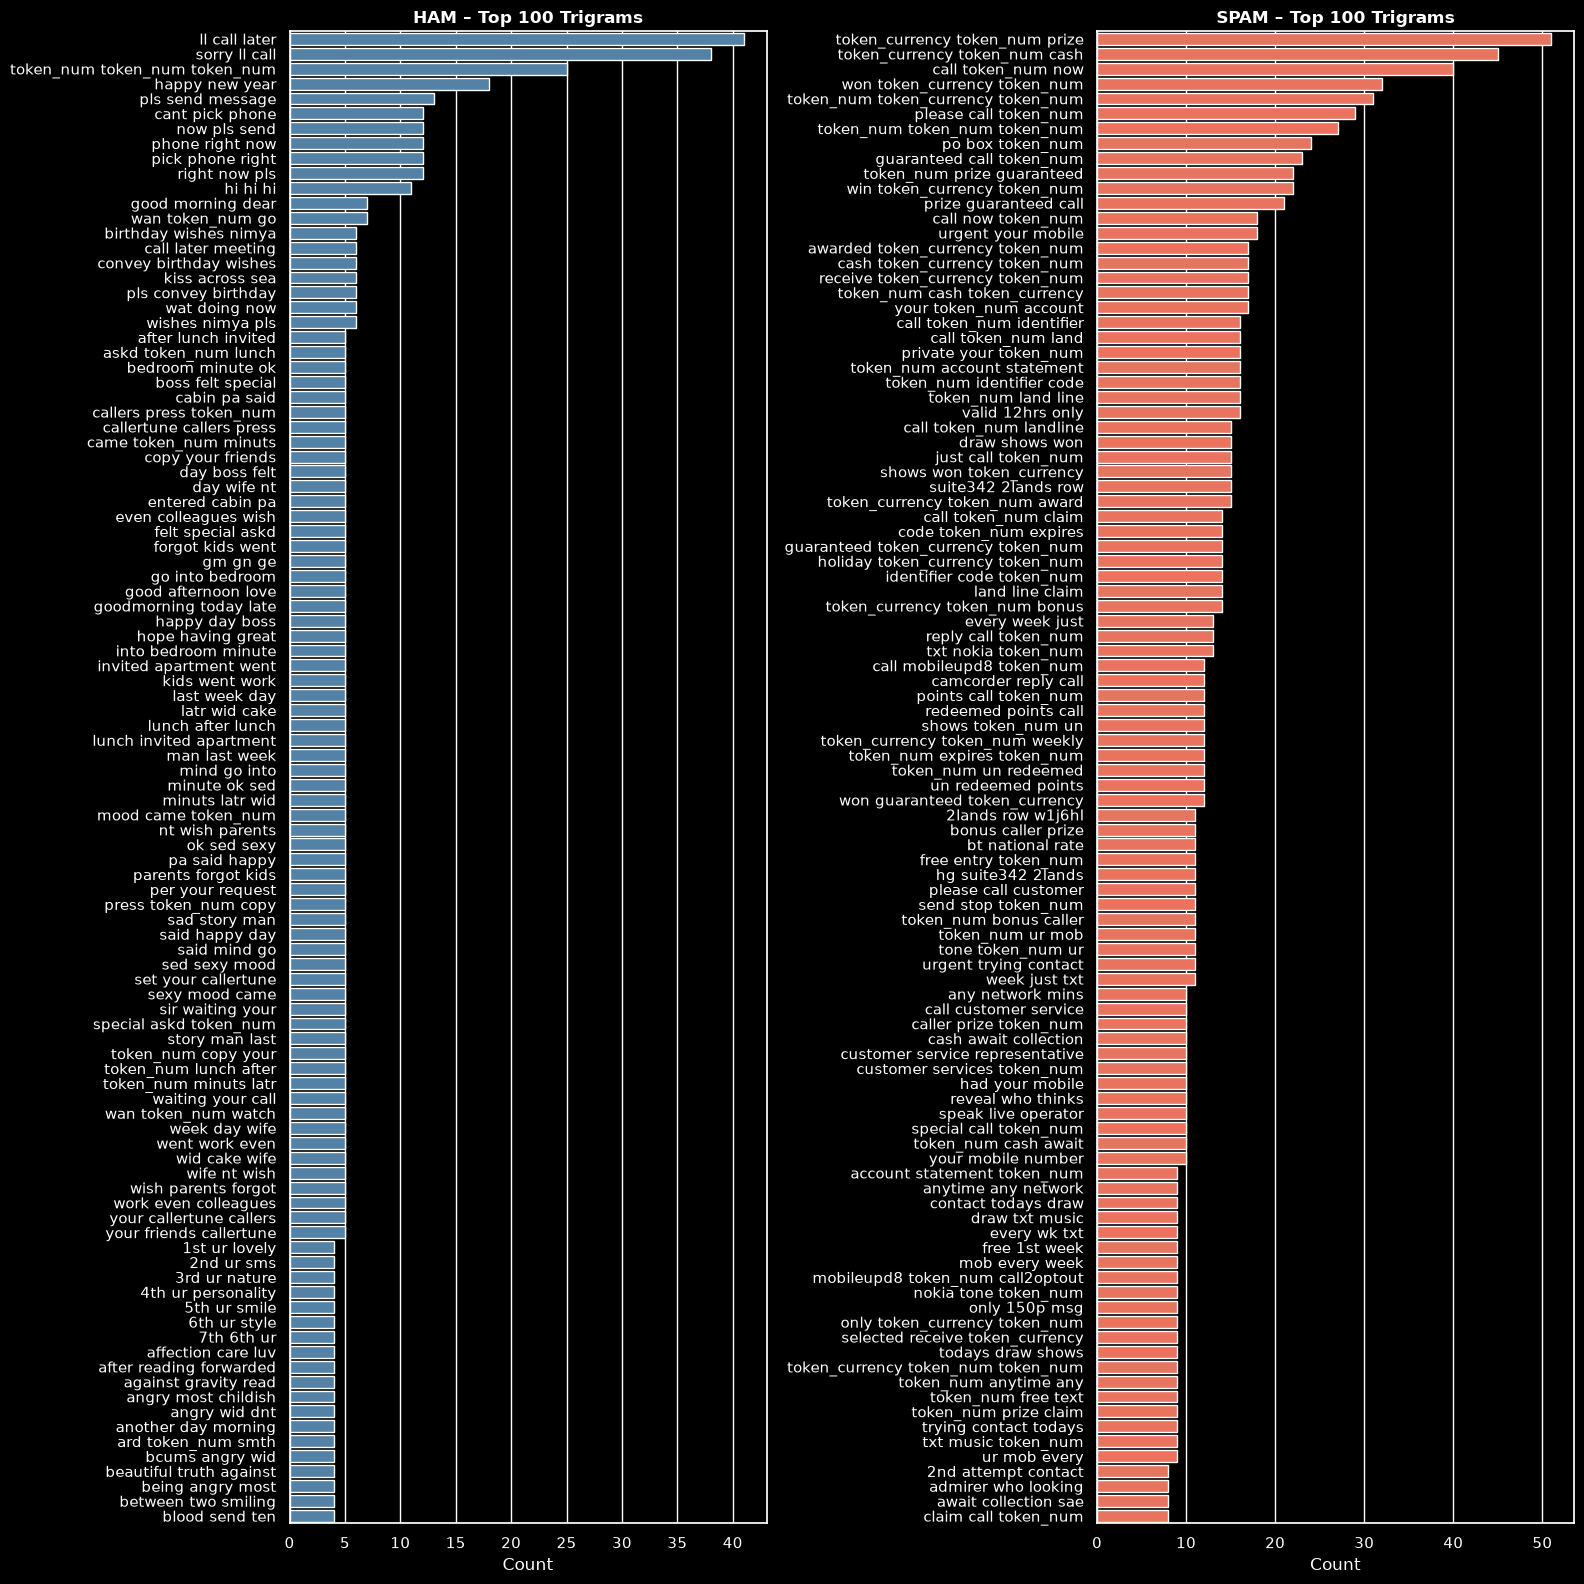

In [9]:
TOP_K      = 100
FIG_HEIGHT = 16

df_trigram_ham  = top_ngrams(ham_texts,  n=3, top_k=TOP_K)
df_trigram_spam = top_ngrams(spam_texts, n=3, top_k=TOP_K)

fig, axes = plt.subplots(1, 2, figsize=(16, FIG_HEIGHT))
sns.barplot(data=df_trigram_ham,  x="count", y="ngram", ax=axes[0], color="steelblue")
sns.barplot(data=df_trigram_spam, x="count", y="ngram", ax=axes[1], color="tomato")
axes[0].set_title(f"HAM – Top {TOP_K} Trigrams",  fontweight="bold")
axes[1].set_title(f"SPAM – Top {TOP_K} Trigrams", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Count")
    ax.set_ylabel("")
plt.tight_layout()
display(fig)
save_figure(fig, OUTPUTS / "03_trigrams_by_class.png")

## Observations

**SPAM bigrams** reveal formulaic templates: `free entry`, `win prize`, `text stop`,
`call now`, `per week`. Spammers reuse a small set of high-engagement phrases.

**HAM bigrams** are conversational and varied: `let know`, `going get`, `come home`.
No phrase dominates because natural conversation is diverse.

**SPAM trigrams** expose the call-to-action structure of spam: `free entry weekly`,
`win cash prize`, `reply stop stop`. These are nearly unique to the SPAM class.

**Practical implication for the classifier (Task 4):** Including bigrams in the
TF-IDF representation (`ngram_range=(1, 2)`) lets the model capture these
two-word spam patterns that unigrams alone would miss.